# 12 · Rung 2: ST-GAT, and does the graph actually help?

**Objective.** Add the road graph to the GRU from notebook 11 with **graph attention**, then prove that any gain comes from the edges and not from extra parameters, using a twin network with every edge removed.

**Concept.** After the GRU has summarised each sensor's hour into a vector, a **graph attention layer** (GAT, Veličković et al. 2018) lets every sensor update its vector from its neighbours:

`h_i' = Σ_j α_ij · W h_j`, where the weights `α_ij` are *learned from the vectors themselves* and sum to 1 over the neighbours of `i`.

So the model can decide, per window, "right now the sensor 400 m upstream matters more than the one across the interchange".

| Design choice | What we did | Why |
|---|---|---|
| two attention convs per layer | one over upstream edges (j → i), one over downstream (i → j) | traffic arrives from upstream, queues back from downstream |
| `edge_dim = 1` | the road-closeness weight enters the attention score | the graph's distance information is not thrown away |
| self-loops (`fill_value = 1`) | each sensor also attends to itself | it can choose to ignore its neighbours |
| 4 heads, 2 layers | 2 hops of neighbourhood per forecast | same reach as DCRNN's K = 2 |
| residual + LayerNorm | `h + GAT(h)` | the graph adds to the GRU summary instead of replacing it |
| **no-edge twin** | identical code, `use_graph=False`, identical parameter count | the only difference is the edges: a clean ablation |

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}")

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import json
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from src import preprocessing as pp, visualization as viz, evaluation as ev
from src.graph_utils import load_graph_artifacts
from deep_learning.dl.data import WindowData
from deep_learning.dl import engine
from deep_learning.dl.models import build
from deep_learning.dl.models.st_gat import directed_edges

viz.apply_style()
ctx = pp.load_context()
adj = load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids).adjacency
data = WindowData.from_context(ctx, "cpu")
SEEDS = (42, 1, 2)
M = config.ARTIFACTS / "metrics"
twin, gat = build("st_gat_noedge", adj, d_model=128), build("st_gat", adj, d_model=128)
print(f"parameters: ST-GAT {engine.count_parameters(gat):,} | no-edge twin {engine.count_parameters(twin):,}")
assert engine.count_parameters(gat) == engine.count_parameters(twin)

parameters: ST-GAT 328,188 | no-edge twin 328,188


## 1 · Hyper-parameter search (validation only)

A small grid: learning rate {3e-4, 1e-3, 3e-3} × width {64, 128}, 25 epochs each, seed 42, for **both** ST-GAT and the twin. The twin gets its own search so it is not handicapped by settings tuned for the graph model. Nothing here looks at the test set.

In [3]:
rows = []
for model in ("st_gat", "st_gat_noedge"):
    for lr in ("0.0003", "0.001", "0.003"):
        for w in (64, 128):
            s = json.loads((M / f"dl_{model}_s42_lr{lr}_w{w}_summary.json").read_text())
            rows.append({"model": model, "lr": float(lr), "width": w, "val MAE": s["best_val_mae_mph"], "best epoch": s["best_epoch"]})
search = pd.DataFrame(rows)
display(search.pivot_table(index=["model", "width"], columns="lr", values="val MAE").round(3))
best = search.loc[search.groupby("model")["val MAE"].idxmin()]
display(best.set_index("model").round(3))

lr                   0.0003  0.0010  0.0030
model         width                        
st_gat        64      2.888   2.831   2.818
              128     2.832   2.796   2.814
st_gat_noedge 64      3.028   2.980   2.959
              128     2.976   2.950   2.970

,lr,width,val MAE,best epoch
model,,,,
st_gat,0.001,128,2.796,21
st_gat_noedge,0.001,128,2.950,21


Both models choose **lr 1e-3, width 128**, so the final comparison uses one shared setting. Note that the best epoch is often 21–25 of 25: the search runs were still improving, which is why the final runs get up to 60 epochs.

The whole grid spans only ~0.09 mph for ST-GAT, while the gap *between* ST-GAT and the twin is 0.14–0.16 mph at every one of the six settings. The graph effect does not depend on lucky tuning.

## 2 · Final runs: three seeds each

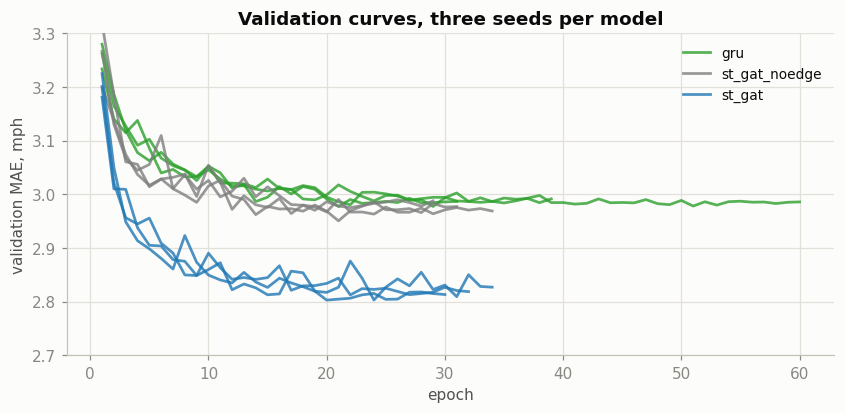

val MAE        best epoch         s / epoch       
                 mean    std       mean     std      mean    std
model                                                           
gru             2.977  0.000     33.667  15.535    34.343  0.028
st_gat          2.806  0.006     22.000   2.000    55.525  0.013
st_gat_noedge   2.961  0.010     21.333   2.517    42.248  0.076

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
seed_rows = []
for model, colour in (("gru", "C2"), ("st_gat_noedge", "C7"), ("st_gat", "C0")):
    for s in SEEDS:
        run = f"dl_{model}_s{s}"
        h = pd.read_csv(M / f"{run}_history.csv")
        sm = json.loads((M / f"{run}_summary.json").read_text())
        ax.plot(h.epoch, h.val_mae_mph, c=colour, alpha=.8, label=model if s == 42 else None)
        seed_rows.append({"model": model, "seed": s, "val MAE": sm["best_val_mae_mph"], "best epoch": sm["best_epoch"],
                          "s / epoch": h.seconds.mean()})
ax.set(xlabel="epoch", ylabel="validation MAE, mph", title="Validation curves, three seeds per model", ylim=(2.7, 3.3))
ax.legend(); plt.show()
seeds = pd.DataFrame(seed_rows)
display(seeds.groupby("model")[["val MAE", "best epoch", "s / epoch"]].agg(["mean", "std"]).round(3))

## 3 · The ablation on the test set

The decisive table. Same windows, same mask, same training recipe, same parameter count; the only difference between rows 2 and 3 is the edges.

In [5]:
keys = ["xgboost_spatial"] + [f"dl_{m}_s{s}" for m in ("gru", "st_gat_noedge", "st_gat") for s in SEEDS]
preds, y, ymask, origins, horizons, _ = ev.load_aligned(keys, "test", ctx.speed, ctx.mask)
valid = ev.common_valid_mask(preds, ymask)
t = ev.metrics_by_horizon(preds, y, valid, horizons)
mae = t.pivot(index="model", columns="horizon_min", values="MAE")
mae["family"] = [k.rsplit("_s", 1)[0] if k.startswith("dl_") else k for k in mae.index]
abl = mae.groupby("family").agg(["mean", "std"]).loc[["xgboost_spatial", "dl_gru", "dl_st_gat_noedge", "dl_st_gat"]]
display(abl.round(3))
fam = mae.groupby("family").mean()
gain = (fam.loc["dl_st_gat_noedge"] - fam.loc["dl_st_gat"])
print("graph gain (no-edge twin minus ST-GAT), mph:", gain.round(3).to_dict())
print("largest seed std of any DL family:", round(float(mae.groupby('family').std().drop('xgboost_spatial').max().max()), 3))

horizon_min           5            15            30            60       
                   mean    std   mean    std   mean    std   mean    std
family                                                                  
xgboost_spatial   2.230    NaN  2.759    NaN  3.182    NaN  3.651    NaN
dl_gru            2.316  0.002  2.824  0.001  3.216  0.002  3.610  0.014
dl_st_gat_noedge  2.311  0.002  2.817  0.009  3.201  0.012  3.577  0.010
dl_st_gat         2.223  0.010  2.676  0.010  3.053  0.013  3.470  0.012

graph gain (no-edge twin minus ST-GAT), mph: {5: 0.088, 15: 0.141, 30: 0.148, 60: 0.107}
largest seed std of any DL family: 0.014


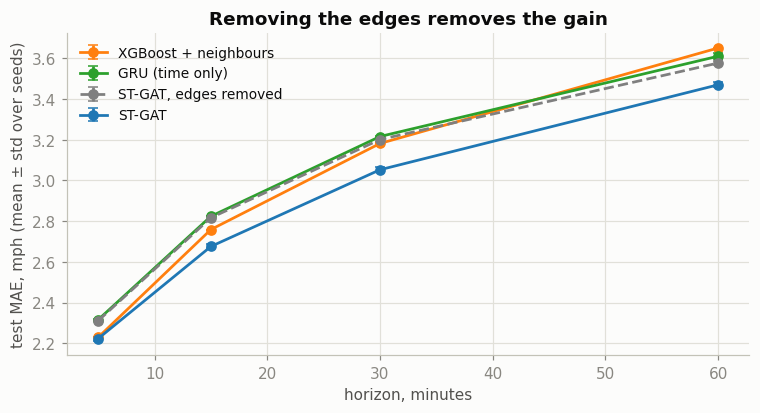

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for f, style, lab in [("xgboost_spatial", "C1-", "XGBoost + neighbours"), ("dl_gru", "C2-", "GRU (time only)"),
                      ("dl_st_gat_noedge", "C7--", "ST-GAT, edges removed"), ("dl_st_gat", "C0-", "ST-GAT")]:
    m, s = abl.loc[f].xs("mean", level=1), abl.loc[f].xs("std", level=1).fillna(0)
    ax.errorbar(m.index, m.values, yerr=s.values, fmt=style, marker="o", capsize=3, label=lab)
ax.set(xlabel="horizon, minutes", ylabel="test MAE, mph (mean ± std over seeds)", title="Removing the edges removes the gain")
ax.legend(); plt.show()

**Reading it.**

* The twin is barely better than the plain GRU: an extra attention layer *without edges* is just more parameters.
* With edges, the error drops at every horizon: about 0.09 mph at 5 minutes and 0.11–0.15 mph at 15–60 minutes, roughly 10× the seed standard deviation. The gain is largest at 15–30 minutes, about the time congestion needs to travel one or two sensors along the freeway.
* ST-GAT is the first model that beats XGBoost + neighbours at **every** horizon.

## 4 · What does the attention look at?

Run the seed-42 model over the test windows and record the attention weights of layer 1, averaged over heads and windows. These are saved for the dashboard's *Graph lens* page.

In [7]:
gat = build("st_gat", adj, d_model=128)
engine.load_weights(gat, config.ARTIFACTS / "models" / "dl_st_gat_s42.pt"); gat.eval()
ei, w = directed_edges(adj)                      # original road edges, src -> dst
src, dst = ei.numpy()
N = adj.shape[0]
key = {(int(a), int(b)): e for e, (a, b) in enumerate(zip(src, dst))}
up_sum, down_sum, count = np.zeros(len(src)), np.zeros(len(src)), 0
test_origins = data.origins["test"][::6]         # every 30 min of the test period: ~1,150 windows
with torch.no_grad():
    for i in range(0, len(test_origins), 64):
        b = data.batch(test_origins[i:i + 64])
        _, att = gat(b, return_attention=True)
        for direction, acc in (("upstream", up_sum), ("downstream", down_sum)):
            e_idx, alpha = att[0][direction]
            s_, d_ = (e_idx % N).numpy()
            a = alpha.mean(1).numpy()
            keep = s_ != d_                      # drop the self-loops GATConv added
            # upstream conv: message s_ -> d_ follows the road edge s_ -> d_
            # downstream conv uses flipped edges, so message s_ -> d_ is road edge d_ -> s_
            pairs = zip(s_[keep], d_[keep]) if direction == "upstream" else zip(d_[keep], s_[keep])
            np.add.at(acc, [key[(int(p), int(q))] for p, q in pairs], a[keep])
        count += len(b["x"])
up_mean, down_mean = up_sum / count, down_sum / count
np.savez(M / "dl_st_gat_attention.npz", src=src, dst=dst, up_mean=up_mean, down_mean=down_mean, road_weight=w.numpy()[:, 0])
print(f"{count:,} test windows, {len(src):,} edges -> saved dl_st_gat_attention.npz")

1,151 test windows, 1,515 edges -> saved dl_st_gat_attention.npz


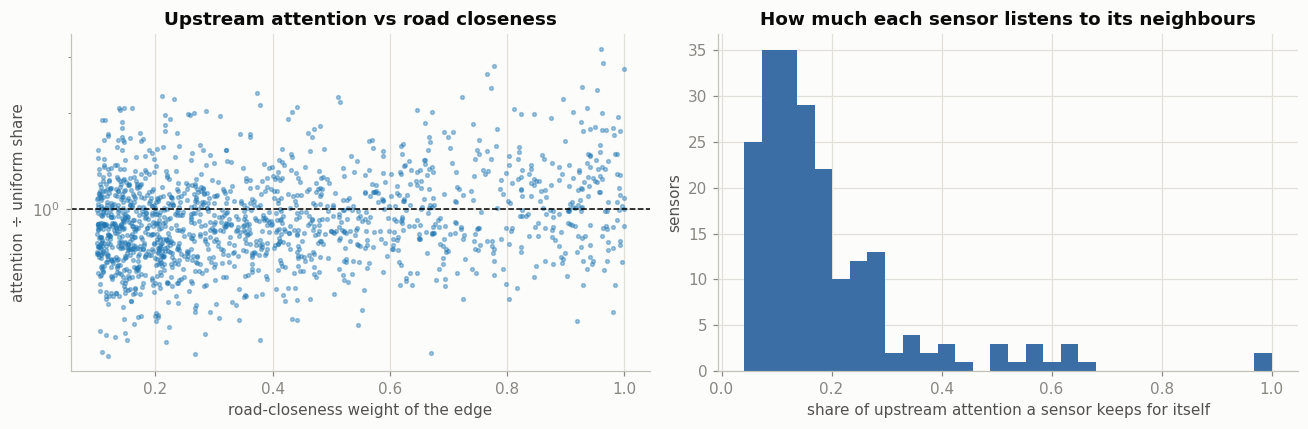

median self-share 0.15; correlation (attention ratio, road weight) 0.24


In [8]:
indeg = np.bincount(dst, minlength=N)
uniform = 1 / (indeg[dst] + 1)                   # what attention would be with no preference (+1 = self-loop)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.scatter(w.numpy()[:, 0], up_mean / uniform, s=6, alpha=.4)
a1.axhline(1, c="k", lw=1, ls="--")
a1.set(xlabel="road-closeness weight of the edge", ylabel="attention ÷ uniform share", title="Upstream attention vs road closeness", yscale="log")
self_share = 1 - np.bincount(dst, weights=up_mean, minlength=N)
a2.hist(self_share, bins=30, color="#3b6ea5")
a2.set(xlabel="share of upstream attention a sensor keeps for itself", ylabel="sensors", title="How much each sensor listens to its neighbours")
plt.tight_layout(); plt.show()
print(f"median self-share {np.median(self_share):.2f}; correlation (attention ratio, road weight) "
      f"{np.corrcoef(w.numpy()[:, 0], up_mean / uniform)[0, 1]:.2f}")

**Reading it.** Attention is far from uniform: some edges get several times their "fair share", others almost nothing. Attention is only loosely tied to the fixed road-closeness weight, which is the point of learning it. Careful: attention weights show *where the model looks*, not *why* it is right. They are a lens, not an explanation.

## Common mistakes

* **Ablating by deleting the layer.** That changes the parameter count too; then you cannot tell edges from capacity apart.
* **Undirected edges.** `to_undirected()` would let a downstream jam and upstream inflow share one weight.
* **Forgetting batching offsets.** Stacking B graphs without shifting node ids by `b · N` silently connects every window to window 0.
* **Reading attention as causality.** High attention on an edge does not prove that sensor causes the forecast.

## Check yourself

1. Why does the twin have exactly the same number of parameters as ST-GAT?
2. Two layers of attention: how many edges away can information travel?
3. The graph gain is ~0.11 mph at 60 min. What evidence says it is not seed luck?
4. Why might attention ignore a short edge across an interchange?